# **Import Libraries**

In [1]:
import numpy as np
import pandas as pd 
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics

# **Load data and inspection**

In [2]:
df = pd.read_csv('/kaggle/input/ibm-hr-analytics-employee-attrition-performance/WA_Fn-UseC_-HR-Employee-Attrition.csv')
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

# **Preprocessing**

In [5]:
df = df.drop(['EmployeeCount', 'Over18', 'StandardHours'], axis = 1)
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,3,4,1,6,3,3,2,2,2,2


In [6]:
df.tail()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,2061,3,...,3,3,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,2062,4,...,3,1,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,2064,2,...,4,2,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,2065,4,...,3,4,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,2068,2,...,3,1,0,6,3,4,4,3,1,2


# **Data Visualization**

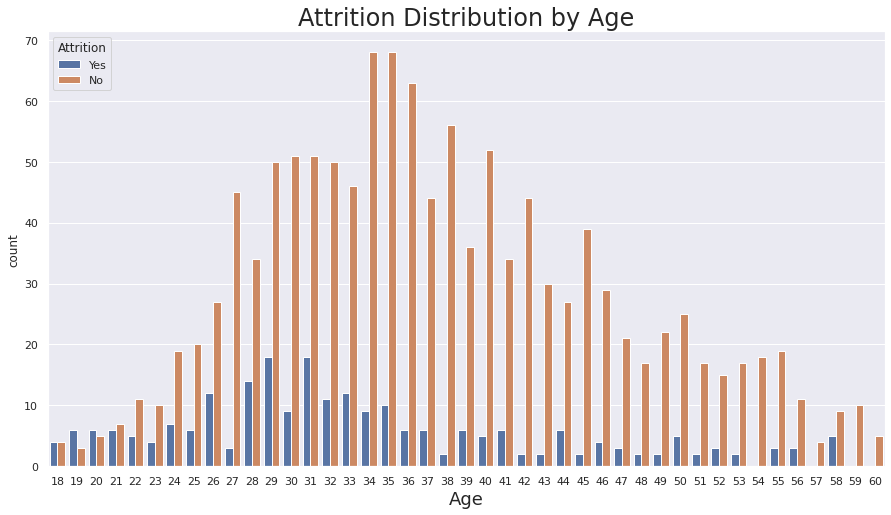

In [7]:
sns.set(style="darkgrid")
sns.set(rc={"figure.figsize":(15, 8)})
ax = sns.countplot(x='Age', hue="Attrition", data=df)
plt.title('Attrition Distribution by Age', fontsize=24)
plt.xlabel('Age', fontsize=18)
plt.show()

The age under 22 employees are more likely to leave, followed by the age group between 22 and 29. After 30, employees' attrition rate goes down.

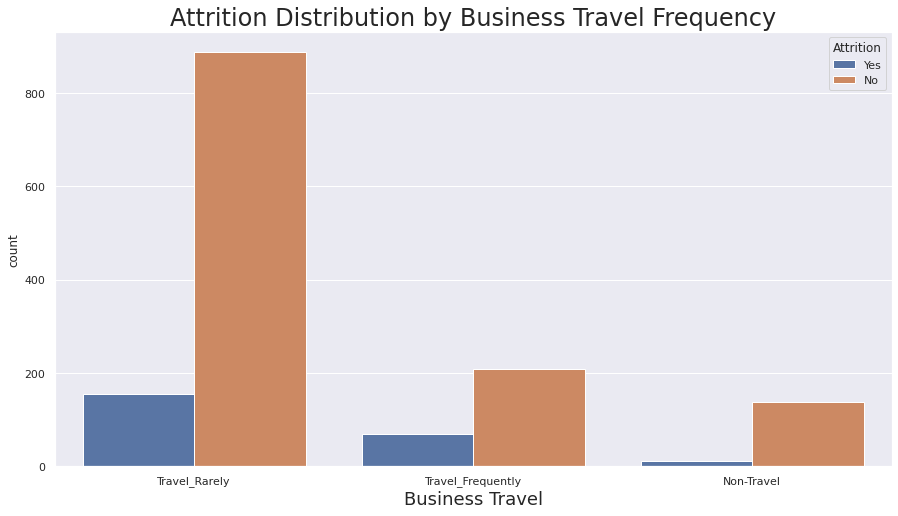

In [8]:
sns.set(style="darkgrid")
sns.set(rc={"figure.figsize":(15, 8)})
ax = sns.countplot(x='BusinessTravel', hue="Attrition", data=df)
plt.title('Attrition Distribution by Business Travel Frequency', fontsize=24)
plt.xlabel('Business Travel', fontsize=18)
plt.show()

The employees who travel frequently have a higher possibility to leave.

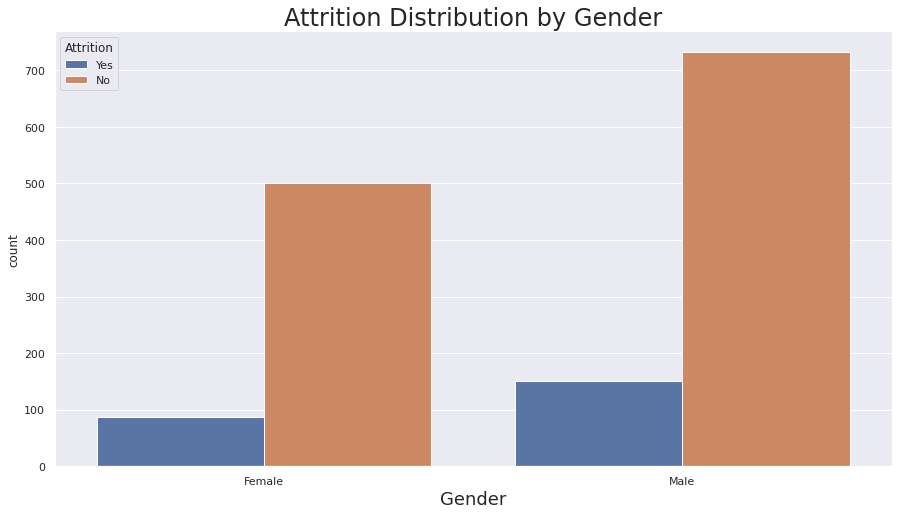

In [9]:
sns.set(style="darkgrid")
sns.set(rc={"figure.figsize":(15, 8)})
ax = sns.countplot(x='Gender', hue="Attrition", data=df)
plt.title('Attrition Distribution by Gender', fontsize=24)
plt.xlabel('Gender', fontsize=18)
plt.show()

No significant difference shows between attrition rates of different genders. 

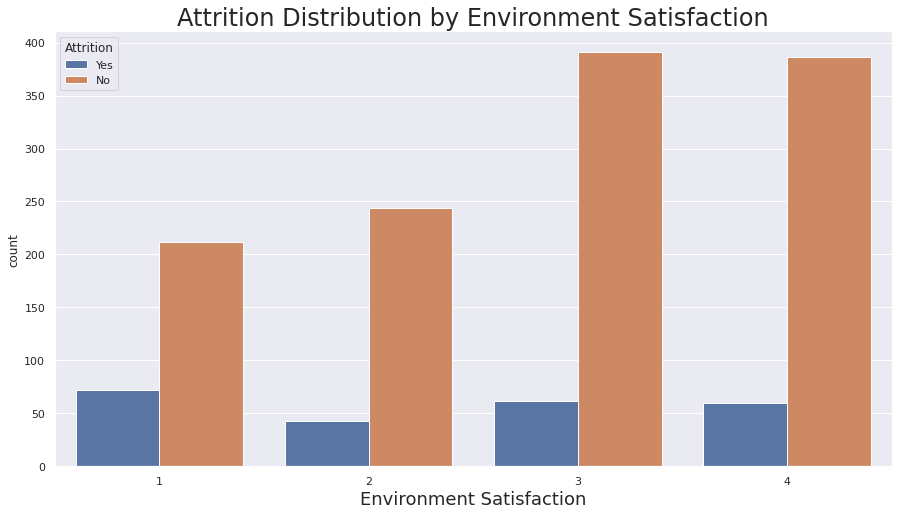

In [10]:
sns.set(style="darkgrid")
sns.set(rc={"figure.figsize":(15, 8)})
ax = sns.countplot(x='EnvironmentSatisfaction', hue="Attrition", data=df)
plt.title('Attrition Distribution by Environment Satisfaction', fontsize=24)
plt.xlabel('Environment Satisfaction', fontsize=18)
plt.show()

The employees who have the lowest satisfaction with the working environment are more likely to leave the company.

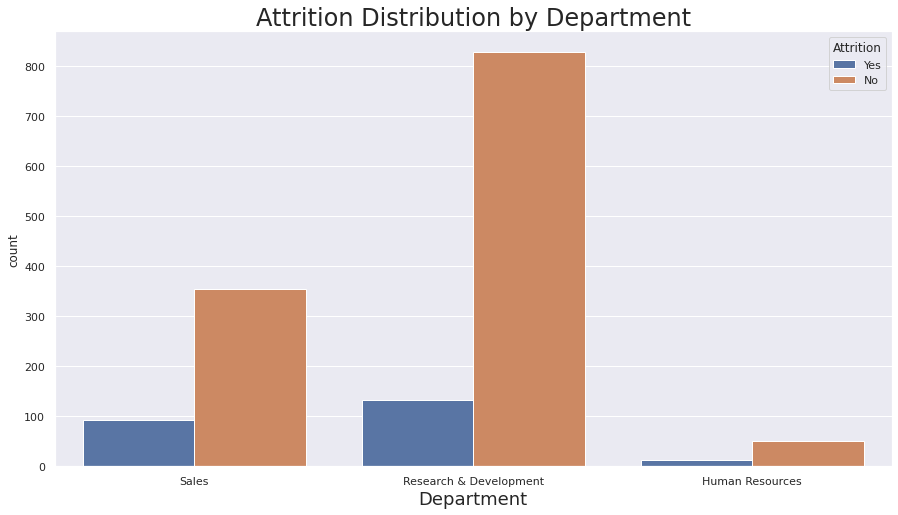

In [11]:
sns.set(style="darkgrid")
sns.set(rc={"figure.figsize":(15, 8)})
ax = sns.countplot(x='Department', hue="Attrition", data=df)
plt.title('Attrition Distribution by Department', fontsize=24)
plt.xlabel('Department', fontsize=18)
plt.show()

Sales Department has the highest attrition rate.

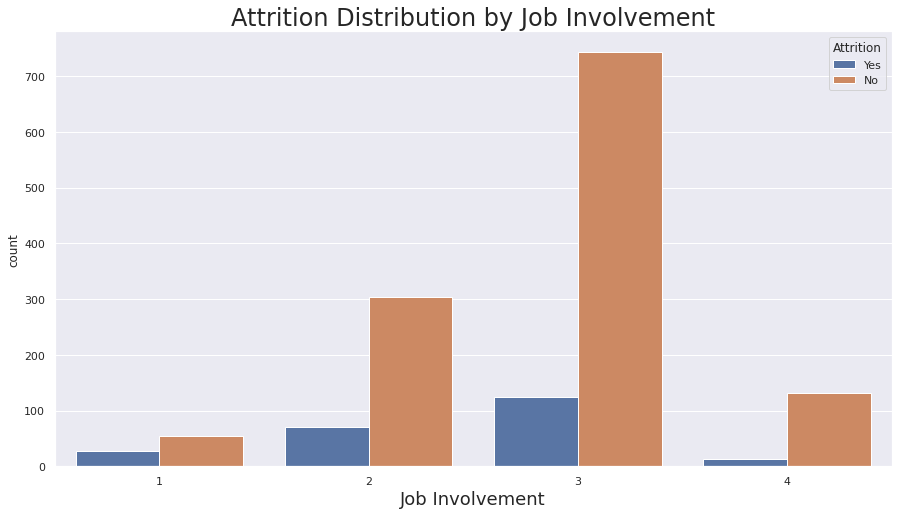

In [12]:
sns.set(style="darkgrid")
sns.set(rc={"figure.figsize":(15, 8)})
ax = sns.countplot(x='JobInvolvement', hue="Attrition", data=df)
plt.title('Attrition Distribution by Job Involvement', fontsize=24)
plt.xlabel('Job Involvement', fontsize=18)
plt.show()

The lower the job involvement, the higher the attrition rate.

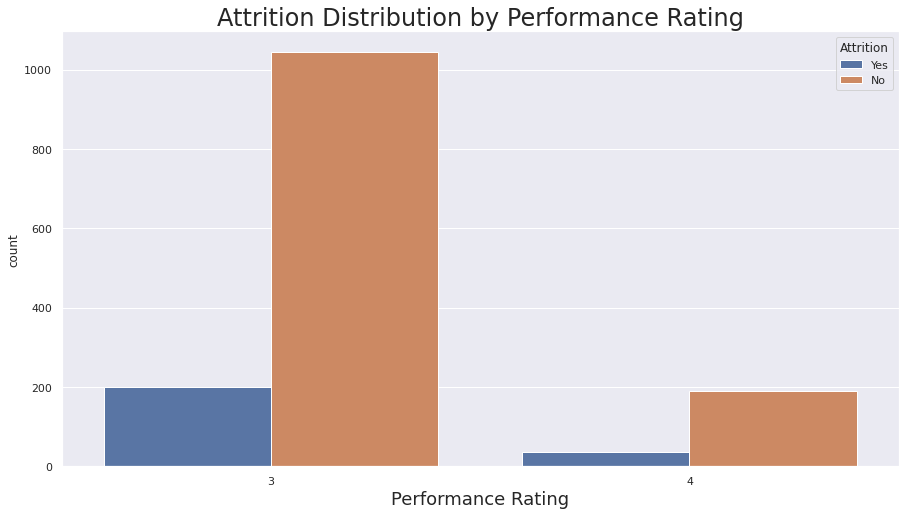

In [13]:
sns.set(style="darkgrid")
sns.set(rc={"figure.figsize":(15, 8)})
ax = sns.countplot(x='PerformanceRating', hue="Attrition", data=df)
plt.title('Attrition Distribution by Performance Rating', fontsize=24)
plt.xlabel('Performance Rating', fontsize=18)
plt.show()

No significant difference shows between attrition rates of different performance ratings. 

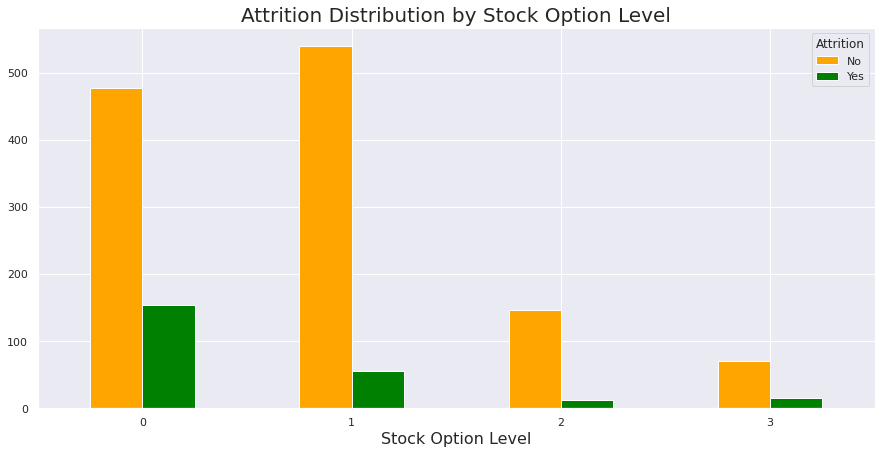

In [14]:
fig,ax = plt.subplots(figsize=(15,7))
stockoption_group = df.groupby(['StockOptionLevel','Attrition']).size().reset_index(name='number')
stockoption_group = stockoption_group.pivot(columns='Attrition', index='StockOptionLevel', values = 'number')
stockoption_group.plot.bar(ax=ax, color=['orange', 'green'])
plt.xticks(rotation=0)
plt.title('Attrition Distribution by Stock Option Level', fontsize=20)
plt.xlabel('Stock Option Level', fontsize=16)
plt.show() 

The employees without a stock option have the highest attrition rate, followed by those with the highest stock-option level.   

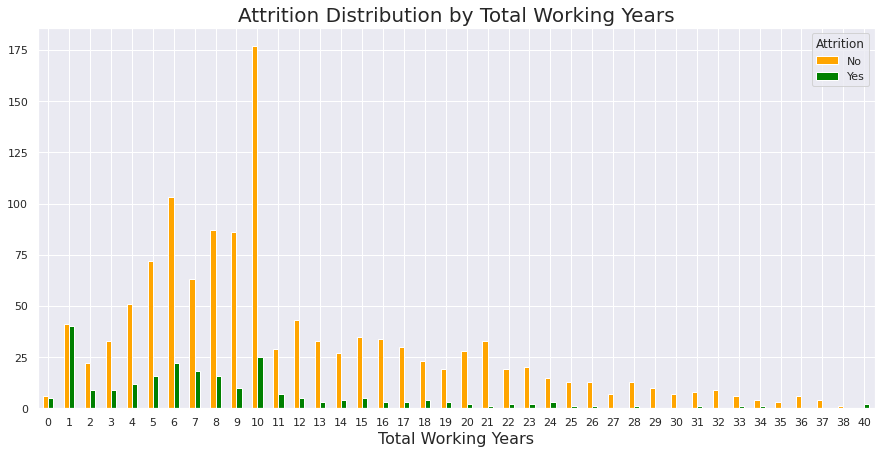

In [15]:
fig,ax = plt.subplots(figsize=(15,7))
working_years_group = df.groupby(['TotalWorkingYears','Attrition']).size().reset_index(name='number')
working_years_group = working_years_group.pivot(columns='Attrition', index='TotalWorkingYears', values = 'number')
working_years_group.plot.bar(ax=ax, color=['orange', 'green'])
plt.xticks(rotation=0)
plt.title('Attrition Distribution by Total Working Years', fontsize=20)
plt.xlabel('Total Working Years', fontsize=16)
plt.show() 

The employees who worked for less than two years have the highest attrition rate (almost 50%), followed by those who worked for 2 to 7 years.

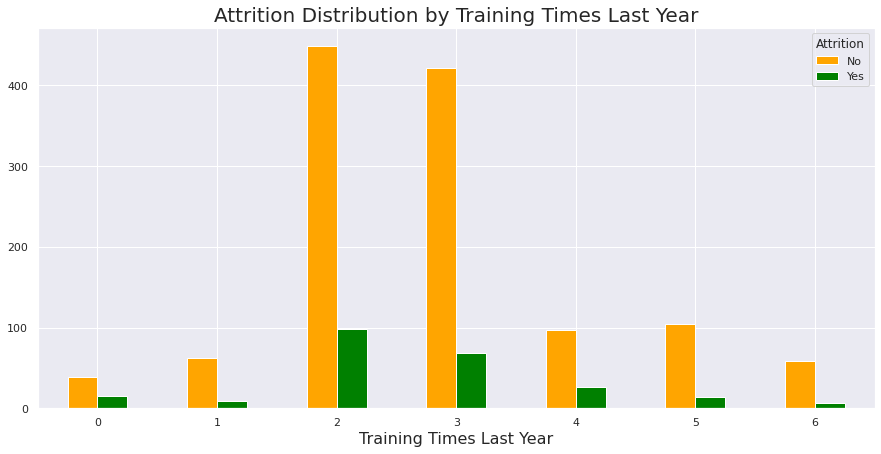

In [16]:
fig,ax = plt.subplots(figsize=(15,7))
training_times_group = df.groupby(['TrainingTimesLastYear','Attrition']).size().reset_index(name='number')
training_times_group = training_times_group.pivot(columns='Attrition', index='TrainingTimesLastYear', values = 'number')
training_times_group.plot.bar(ax=ax, color=['orange', 'green'])
plt.xticks(rotation=0)
plt.title('Attrition Distribution by Training Times Last Year', fontsize=20)
plt.xlabel('Training Times Last Year', fontsize=16)
plt.show() 

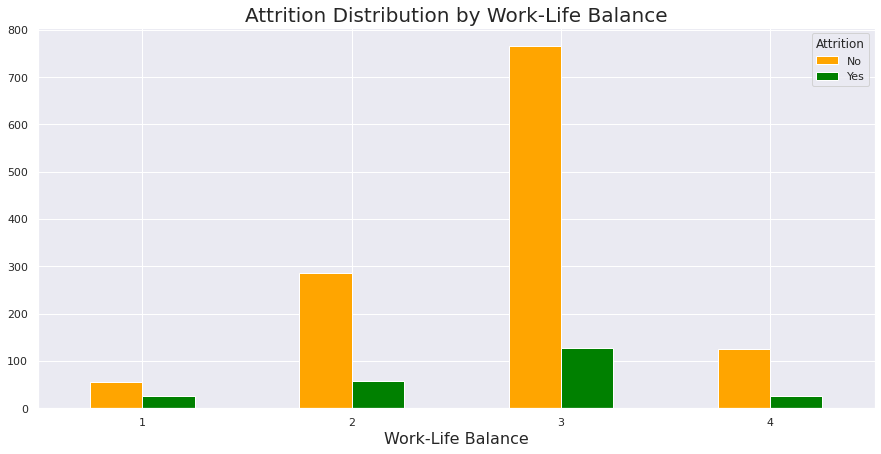

In [17]:
fig,ax = plt.subplots(figsize=(15,7))
work_life_balance = df.groupby(['WorkLifeBalance','Attrition']).size().reset_index(name='number')
work_life_balance = work_life_balance.pivot(columns='Attrition', index='WorkLifeBalance', values = 'number')
work_life_balance.plot.bar(ax=ax, color=['orange', 'green'])
plt.xticks(rotation=0)
plt.title('Attrition Distribution by Work-Life Balance', fontsize=20)
plt.xlabel('Work-Life Balance', fontsize=16)
plt.show() 

Medium work-life balance brings down the attrition rate.

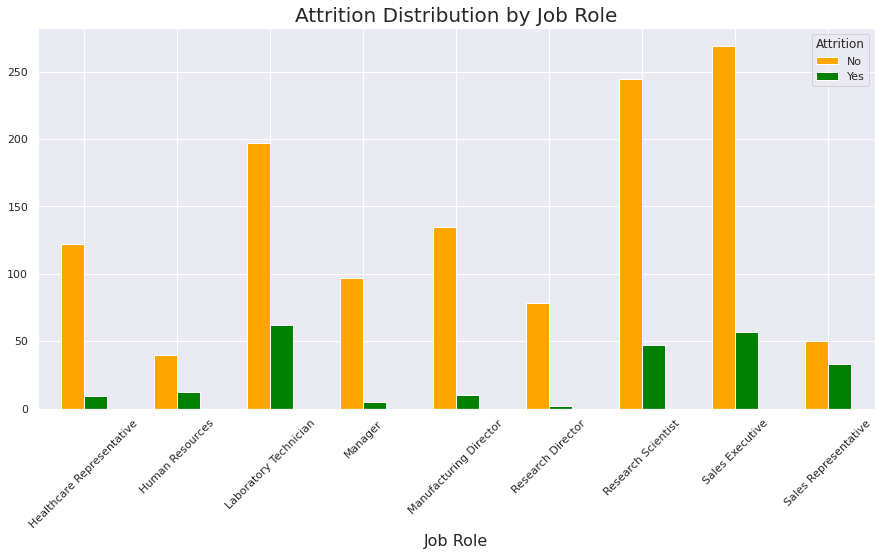

In [18]:
fig,ax = plt.subplots(figsize=(15,7))
job_role = df.groupby(['JobRole','Attrition']).size().reset_index(name='number')
job_role = job_role.pivot(columns='Attrition', index='JobRole', values = 'number')
job_role.plot.bar(ax=ax, color=['orange', 'green'])
plt.xticks(rotation=45)
plt.title('Attrition Distribution by Job Role', fontsize=20)
plt.xlabel('Job Role', fontsize=16)
plt.show() 

Sales Representatives have the highest attrition rate among all job roles in the company, followed by Laboratory Technicians.

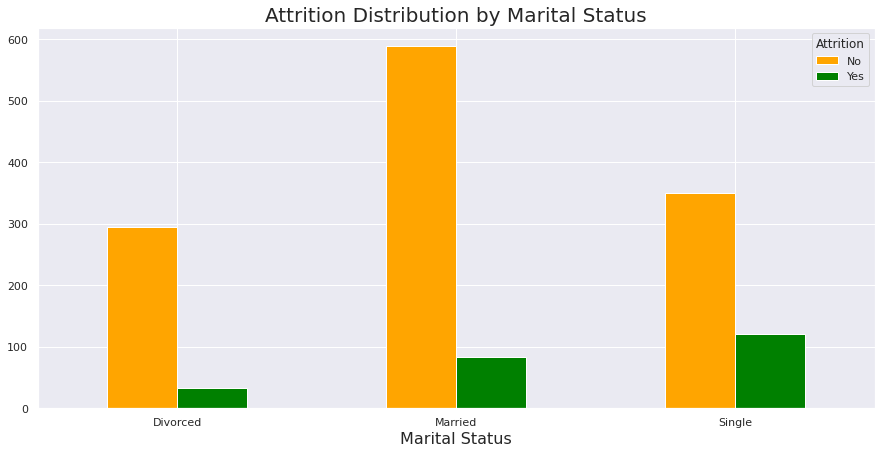

In [19]:
fig,ax = plt.subplots(figsize=(15,7))
marital_status = df.groupby(['MaritalStatus','Attrition']).size().reset_index(name='number')
marital_status = marital_status.pivot(columns='Attrition', index='MaritalStatus', values = 'number')
marital_status.plot.bar(ax=ax, color=['orange', 'green'])
plt.xticks(rotation=0)
plt.title('Attrition Distribution by Marital Status', fontsize=20)
plt.xlabel('Marital Status', fontsize=16)
plt.show() 

The single employees are more likely to leave.

# **Now prepare the dataset for heatmap**

In [20]:
df_2 = df.copy()
df_2['Attrition'] = df_2['Attrition'].apply(lambda x: 0 if x=='No' else 1)
df_2['Gender'] = df_2['Gender'].apply(lambda x: 0 if x=='Male' else 1)
df_2['OverTime'] = df_2['OverTime'].apply(lambda x: 0 if x=='No' else 1)

BusinessTravel_map = {'Non-Travel':0, 'Travel_Rarely':1, 'Travel_Frequently':2}
df_2['BusinessTravel'] = df_2['BusinessTravel'].map(BusinessTravel_map)

MaritalStatus_map = {'Single':0, 'Divorced':1, 'Married':2}
df_2['MaritalStatus'] = df_2['MaritalStatus'].map(MaritalStatus_map)

EducationField_map = {'Other':0, 'Life Sciences':1, 'Medical':2, 'Marketing':3, 'Technical Degree':4,
                     'Human Resources':5}
df_2['EducationField'] = df_2['EducationField'].map(EducationField_map)

JobRole_map = {'Sales Executive':0,'Sales Representative':1,'Laboratory Technician':2,'Manufacturing Director':3,
              'Healthcare Representative':4,'Manager':5,'Research Scientist':6,'Research Director':7,'Human Resources':8}
df_2['JobRole'] = df_2['JobRole'].map(JobRole_map)

Department_map = {'Sales':0, 'Research & Development':1, 'Human Resources':2}
df_2['Department'] = df_2['Department'].map(Department_map)
df_2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 32 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   int64
 2   BusinessTravel            1470 non-null   int64
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   int64
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   int64
 8   EmployeeNumber            1470 non-null   int64
 9   EnvironmentSatisfaction   1470 non-null   int64
 10  Gender                    1470 non-null   int64
 11  HourlyRate                1470 non-null   int64
 12  JobInvolvement            1470 non-null   int64
 13  JobLevel                  1470 non-null   int64
 14  JobRole                   1470 non-null 

Text(0.5, 1.0, 'Correlation Graph')

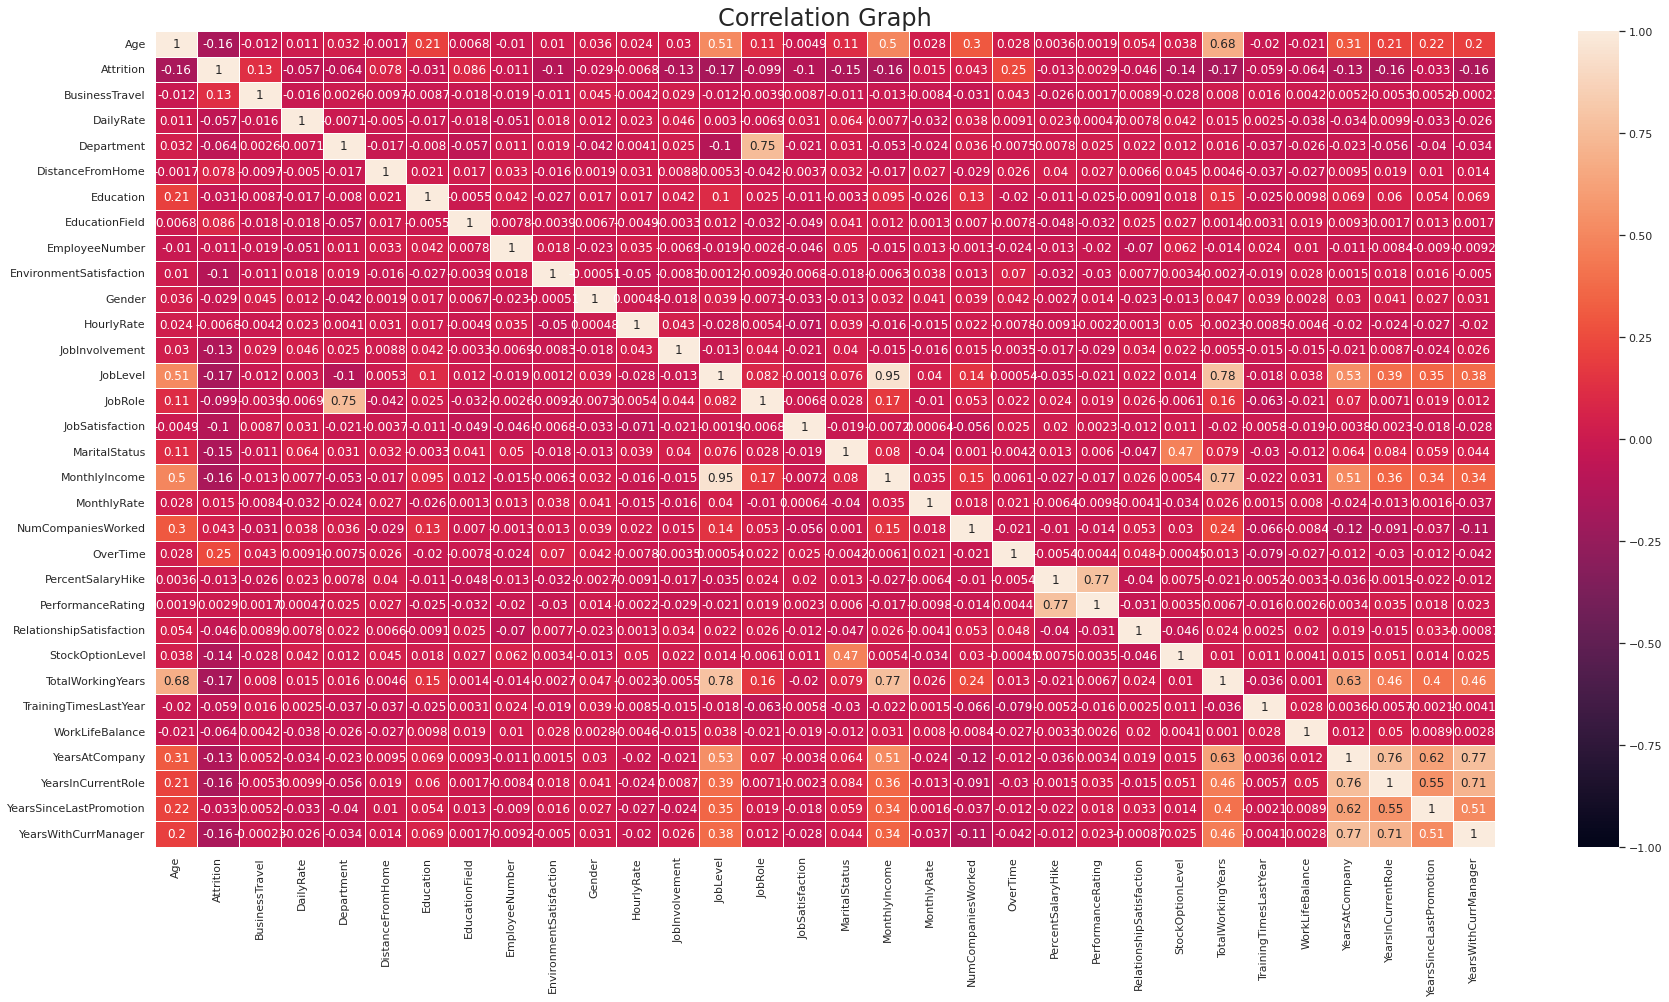

In [21]:
plt.figure(figsize=(30,15))
correlation = sns.heatmap(df_2.corr(), vmin=-1, vmax=1, annot=True, linewidths=1)
correlation.set_title('Correlation Graph', fontdict={'fontsize': 24})

# **Use Random Forest Classifier for Prediction**

In [22]:
X = df_2.drop('Attrition', axis = 1)
y = df_2['Attrition']
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3)

In [23]:
from sklearn.ensemble import RandomForestClassifier
clf=RandomForestClassifier(n_estimators=100, max_depth=3)
clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

In [24]:
from sklearn import metrics
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.8253968253968254


In [25]:
result = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
result

,Actual,Predicted
978,0,0
1415,0,0
553,0,0
1047,0,0
131,0,0
...,...,...
267,0,0
64,0,0
655,0,0
414,1,0


# **Plot the Feature Importance Score**

In [26]:
feature_imp = pd.Series(clf.feature_importances_,index=X.columns).sort_values(ascending=False)
feature_imp

MonthlyIncome               0.129596
TotalWorkingYears           0.105645
OverTime                    0.085202
YearsWithCurrManager        0.074075
JobLevel                    0.073756
YearsAtCompany              0.062365
Age                         0.054096
YearsInCurrentRole          0.043848
StockOptionLevel            0.042392
JobRole                     0.037229
JobSatisfaction             0.032643
EducationField              0.026857
DistanceFromHome            0.024728
DailyRate                   0.023304
MonthlyRate                 0.021621
JobInvolvement              0.019580
MaritalStatus               0.019238
NumCompaniesWorked          0.014841
TrainingTimesLastYear       0.013464
Department                  0.012740
YearsSinceLastPromotion     0.012696
EnvironmentSatisfaction     0.012552
HourlyRate                  0.012388
WorkLifeBalance             0.012356
EmployeeNumber              0.011860
BusinessTravel              0.007367
PercentSalaryHike           0.005509
R

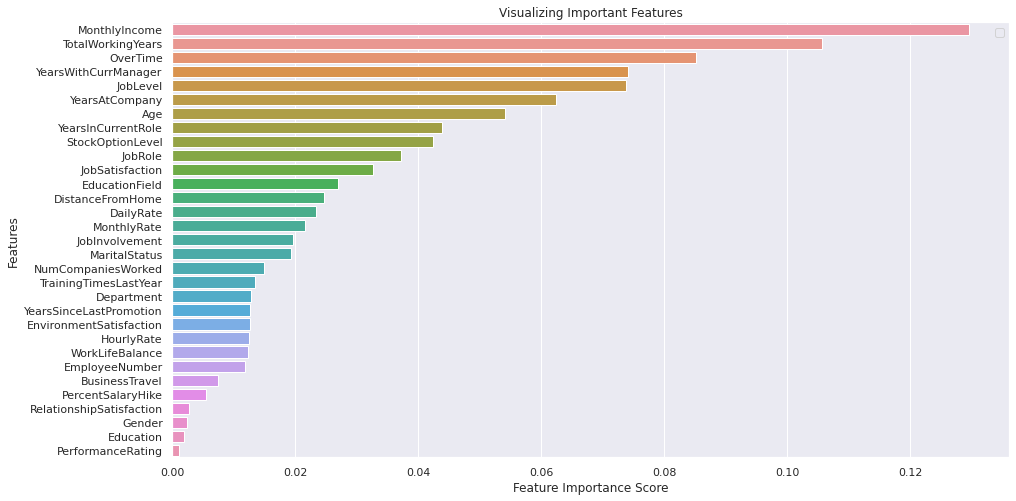

In [27]:
sns.barplot(x=feature_imp, y=feature_imp.index)
sns.set(rc={"figure.figsize": (20,15)})
plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.title("Visualizing Important Features")
plt.legend()
plt.show()

The most important features that affect the attrition rate are monthly income, over time, and total working year.

# **Use Logistic Regression for Prediction**

In [28]:
X = df_2.drop('Attrition', axis = 1)
y = df_2['Attrition']
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=0)

In [29]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression(solver='liblinear')

In [30]:
logreg.fit(X_train, y_train)
y_pred = logreg.predict(X_test)

In [31]:
result_2 = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
result_2

,Actual,Predicted
442,0,0
1091,0,0
981,1,1
785,0,0
1332,1,1
...,...,...
817,0,0
399,0,0
458,0,0
406,0,0


In [32]:
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))
print("Precision:",metrics.precision_score(y_test, y_pred))
print("Recall:",metrics.recall_score(y_test, y_pred))

Accuracy: 0.873015873015873
Precision: 0.75
Recall: 0.3


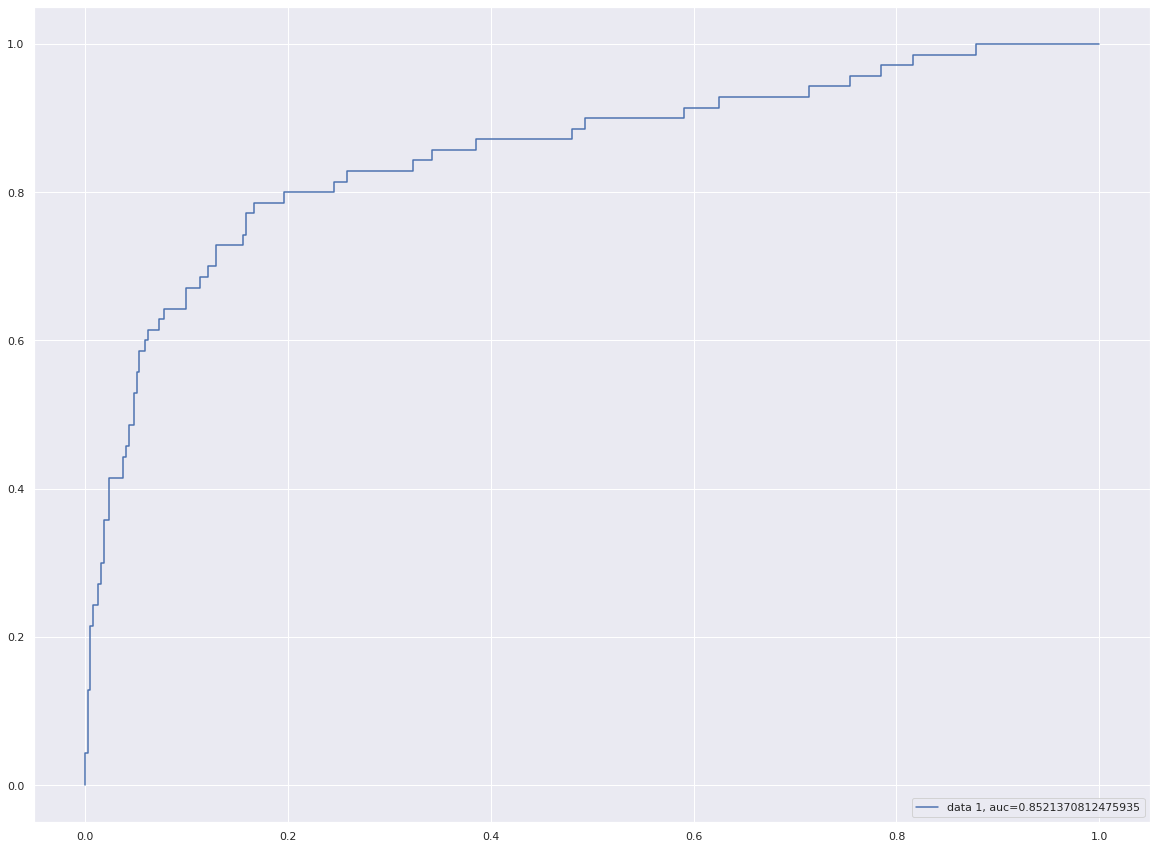

In [33]:
y_pred_proba = logreg.predict_proba(X_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_test, y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)
plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.legend(loc=4)
plt.show()